In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [17]:
DATA = Path("Accidents.csv") # type your full filepath
df = pd.read_csv(DATA)
df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-2047758,Source2,2,2019-06-12 10:10:56,2019-06-12 10:55:58,30.641211,-91.153481,NaN,NaN,0.000,...,False,False,False,False,True,False,Day,Day,Day,Day
1,A-4694324,Source1,2,2022-12-03 23:37:14.000000000,2022-12-04 01:56:53.000000000,38.990562,-77.399070,38.990037,-77.398282,0.056,...,False,False,False,False,False,False,Night,Night,Night,Night
2,A-5006183,Source1,2,2022-08-20 13:13:00.000000000,2022-08-20 15:22:45.000000000,34.661189,-120.492822,34.661189,-120.492442,0.022,...,False,False,False,False,True,False,Day,Day,Day,Day
3,A-4237356,Source1,2,2022-02-21 17:43:04,2022-02-21 19:43:23,43.680592,-92.993317,43.680574,-92.972223,1.054,...,False,False,False,False,False,False,Day,Day,Day,Day
4,A-6690583,Source1,2,2020-12-04 01:46:00,2020-12-04 04:13:09,35.395484,-118.985176,35.395476,-118.985995,0.046,...,False,False,False,False,False,False,Night,Night,Night,Night


In [18]:
# === Data Cleaning === 
df_clean = df.drop(columns=["End_Lat", "End_Lng", "Wind_Chill(F)", "Precipitation(in)"])
df_clean = df_clean.dropna()
df_clean.duplicated().sum()

np.int64(0)

In [19]:
# Cleaned Dataset
df_clean.info()
df_clean.describe()

<class 'pandas.DataFrame'>
Index: 456181 entries, 0 to 499999
Data columns (total 42 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     456181 non-null  str    
 1   Source                 456181 non-null  str    
 2   Severity               456181 non-null  int64  
 3   Start_Time             456181 non-null  str    
 4   End_Time               456181 non-null  str    
 5   Start_Lat              456181 non-null  float64
 6   Start_Lng              456181 non-null  float64
 7   Distance(mi)           456181 non-null  float64
 8   Description            456181 non-null  str    
 9   Street                 456181 non-null  str    
 10  City                   456181 non-null  str    
 11  County                 456181 non-null  str    
 12  State                  456181 non-null  str    
 13  Zipcode                456181 non-null  str    
 14  Country                456181 non-null  str    
 15 

,Severity,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph)
count,456181.000000,456181.000000,456181.000000,456181.000000,456181.000000,456181.000000,456181.000000,456181.000000,456181.000000
mean,2.203327,36.189211,-94.604880,0.572737,61.849253,64.421427,29.511263,9.107437,7.686465
std,0.479828,5.116876,17.315364,1.775159,19.025493,22.770062,1.017821,2.647917,5.424911
min,1.000000,24.562117,-124.497420,0.000000,-29.000000,1.000000,19.360000,0.000000,0.000000
25%,2.000000,33.335219,-117.165276,0.000000,49.000000,48.000000,29.330000,10.000000,4.600000
50%,2.000000,35.824685,-87.700971,0.037000,64.000000,67.000000,29.830000,10.000000,7.000000
75%,2.000000,40.115257,-80.375587,0.480000,76.000000,84.000000,30.020000,10.000000,10.400000
max,4.000000,48.999569,-67.484130,193.479996,196.000000,100.000000,38.440000,100.000000,822.800000


In [20]:
# === Time Patterns ===

df_clean["Start_Time"] = pd.to_datetime(df_clean["Start_Time"], format="mixed", errors="coerce")
df_clean["End_Time"] = pd.to_datetime(df_clean["End_Time"], format="mixed", errors="coerce")

# Accidents by Year
df_clean["Year"] = df_clean["Start_Time"].dt.year
by_year = df_clean["Year"].value_counts().sort_index()

# Accidents by Month
df_clean["Month"] = df_clean["Start_Time"].dt.month
by_month = df_clean["Month"].value_counts().sort_index()

# Accidents by Day
df_clean["Day"] = df_clean["Start_Time"].dt.day
by_day = df_clean["Day"].value_counts().sort_index()

# Accidents by Hour
df_clean["Hour"] = df_clean["Start_Time"].dt.hour
by_hour = df_clean["Hour"].value_counts().sort_index()


print(f"Accidents by Year:\n{by_year}\n")
print(f"Accidents by Month:\n{by_month}\n")
print(f"Accidents by Day:\n{by_day}\n")
print(f"Accidents by Hour:\n{by_hour}\n")

Accidents by Year:
Year
2016     21319
2017     37336
2018     45985
2019     57601
2020     73057
2021     97824
2022    108084
2023     14975
Name: count, dtype: int64

Accidents by Month:
Month
1     44186
2     39332
3     32555
4     35895
5     33695
6     33842
7     30138
8     34810
9     38027
10    39686
11    44079
12    49936
Name: count, dtype: int64

Accidents by Day:
Day
1     14452
2     14497
3     14500
4     14350
5     14535
6     14678
7     14564
8     14784
9     14627
10    14747
11    15453
12    15957
13    15461
14    15595
15    15671
16    15688
17    15414
18    15535
19    15554
20    15542
21    15574
22    16392
23    16685
24    14735
25    13628
26    13950
27    14345
28    14205
29    13085
30    13718
31     8260
Name: count, dtype: int64

Accidents by Hour:
Hour
0      6656
1      5617
2      5514
3      4806
4      9150
5     12915
6     22715
7     33136
8     33270
9     21086
10    20434
11    21025
12    21337
13    23736
14    27242
15    3

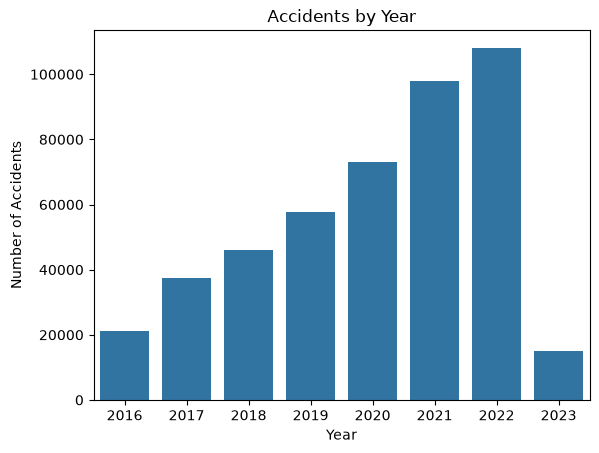

In [21]:
sns.countplot(x="Year", data=df_clean)

plt.title("Accidents by Year")
plt.xlabel("Year")
plt.ylabel("Number of Accidents")
plt.show()

In [22]:
# === Geographical Patterns ===

# df_clean["State"].value_counts().sort_index().plot(kind="bar", figsize=(12, 6))
# plt.title("Accidents by State")
# plt.xlabel("State")
# plt.ylabel("Number of Accidents")
# plt.show()
# df_clean["City"].value_counts().sort_index()
# df_clean["County"].value_counts().sort_index()
# df_clean["Timezone"].value_counts().sort_values()
df_clean["Street"].value_counts().sort_index()

Street
 1/2 Ave         1
 10 Mile Rd      1
 100th Ave N     1
 100th Ave SE    1
 100th St        1
                ..
Zorn Ave         8
Zunbar Dr        1
Zuni Rd SE       4
Zuni St          5
Zuniga Rd        1
Name: count, Length: 83288, dtype: int64

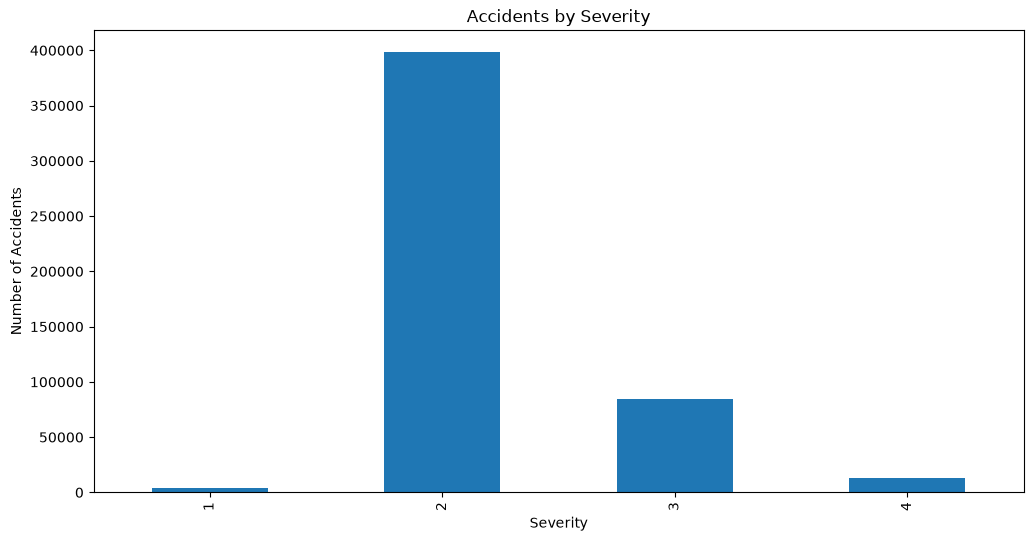

In [23]:
# === Severity Patterns ===
df["Severity"].value_counts().sort_index().plot(kind="bar", figsize=(12, 6))
plt.title("Accidents by Severity")
plt.xlabel("Severity")
plt.ylabel("Number of Accidents")
plt.show()

In [24]:
# === Weather Patterns ===

df_clean["Weather_Condition"].value_counts().sort_index()
df_clean["Temperature(F)"].value_counts().sort_index()
df_clean["Wind_Speed(mph)"].value_counts().sort_index()
df_clean["Visibility(mi)"].value_counts().sort_index()

Visibility(mi)
0.00         489
0.06          15
0.10          47
0.12         132
0.19           3
0.20         457
0.25        1714
0.38          22
0.40           3
0.50        2117
0.60           6
0.63          21
0.75        1304
0.80         433
0.88          13
0.90           1
1.00        6324
1.10           3
1.20         356
1.40           3
1.50         599
1.80         431
1.90           2
2.00        7435
2.20           4
2.50         950
2.80           7
3.00        6948
4.00        7080
4.20           2
5.00        8528
6.00        7490
7.00       12688
8.00        8763
9.00       11284
10.00     368720
10.50          1
11.00          6
12.00         22
13.00        592
15.00        368
20.00        244
23.00          1
25.00         53
30.00        165
35.00         10
40.00        110
45.00         26
50.00        130
58.00          1
60.00          8
65.00          1
70.00         11
75.00         12
76.00          2
78.00          1
80.00         21
100.00         2

In [25]:
# Cleaned Dataset
df_clean.to_csv("Accidents_cleaned.csv", index=False)

In [30]:
unique_counts = df_clean.nunique(dropna=False)

constant_columns = unique_counts[unique_counts <= 1].index.tolist()

print("Columns that can be discarded:")
print(constant_columns)
df_clean2 = df.drop(columns=["End_Lat", "End_Lng", "Wind_Chill(F)", "Precipitation(in)", "Country", "Turning_Loop"])
df_clean2 = df_clean2.dropna()
df_clean2.info()

Columns that can be discarded:
['Country', 'Turning_Loop']
<class 'pandas.DataFrame'>
Index: 456181 entries, 0 to 499999
Data columns (total 40 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     456181 non-null  str    
 1   Source                 456181 non-null  str    
 2   Severity               456181 non-null  int64  
 3   Start_Time             456181 non-null  str    
 4   End_Time               456181 non-null  str    
 5   Start_Lat              456181 non-null  float64
 6   Start_Lng              456181 non-null  float64
 7   Distance(mi)           456181 non-null  float64
 8   Description            456181 non-null  str    
 9   Street                 456181 non-null  str    
 10  City                   456181 non-null  str    
 11  County                 456181 non-null  str    
 12  State                  456181 non-null  str    
 13  Zipcode                456181 non-null  str   

In [34]:
for column in df_clean2.columns:
    print()
    print(df_clean2[column].value_counts(dropna=False).head(10))


ID
A-2047758    1
A-4694324    1
A-5006183    1
A-4237356    1
A-6690583    1
A-1101469    1
A-7222249    1
A-6198239    1
A-4222549    1
A-5924038    1
Name: count, dtype: int64

Source
Source1    261574
Source2    188719
Source3      5888
Name: count, dtype: int64

Severity
2    366655
3     73959
4     11454
1      4113
Name: count, dtype: int64

Start_Time
2021-01-26 16:16:13    20
2021-02-16 06:42:43    10
2021-11-21 18:37:51    10
2021-01-26 16:17:33    10
2020-12-16 13:53:25     9
2017-05-15 09:22:55     8
2021-02-16 06:43:35     8
2021-05-03 06:29:42     7
2019-10-26 08:45:17     7
2021-05-03 06:30:28     6
Name: count, dtype: int64

End_Time
2021-11-22 08:00:00    11
2017-05-15 15:22:55     8
2019-10-26 09:14:51     7
2020-02-07 00:00:00     6
2020-02-08 00:00:00     5
2022-05-02 09:16:27     4
2020-04-08 16:57:07     4
2020-09-16 06:55:00     4
2020-11-04 03:24:29     4
2022-04-22 19:18:27     4
Name: count, dtype: int64

Start_Lat
34.858849    44
25.899170    38
34.858925  

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

decision_df = df_clean2.drop(columns=["Distance(mi)", "Source", "ID", "Description", "Street", "City", "County", "State", "Zipcode", "Airport_Code", "Wind_Direction", "Weather_Condition"])
X = decision_df.drop(columns=["Severity"])
Y = decision_df["Severity"]

# Convert datetime columns into usable numeric features
date_columns = ["Start_Time", "End_Time", "Weather_Timestamp"]

print(X["Start_Time"][0])

# NOTE: might want to clean up the dates to simply have start time, end time, year/month, and month 
for col in date_columns:
    date = pd.to_datetime(X[col], errors="coerce")
    
    X[f"{col}_month"] = date.dt.month
    X[f"{col}_hour"] = date.dt.hour

X = X.drop(columns=date_columns)

# Categorical columns, which are any strings or booleans
categorical_columns = X.select_dtypes(
    include=["string", "bool"]
).columns

#Numerical columns, which are any floats or ints
numeric_columns = X.select_dtypes(
    include=["number"]
).columns

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_columns),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_columns)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("tree", DecisionTreeClassifier(
        max_depth=3,
        class_weight="balanced",
        random_state=42
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

model.fit(X_train, y_train)


2019-06-12 10:10:56


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('tree', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[1,2,3,4]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](33,)","['Start_Lat','Start_Lng','Timezone',...,'Weather_Timestamp_year_month', 'Weather_Timestamp_month','Weather_Timestamp_hour']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,33
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (def

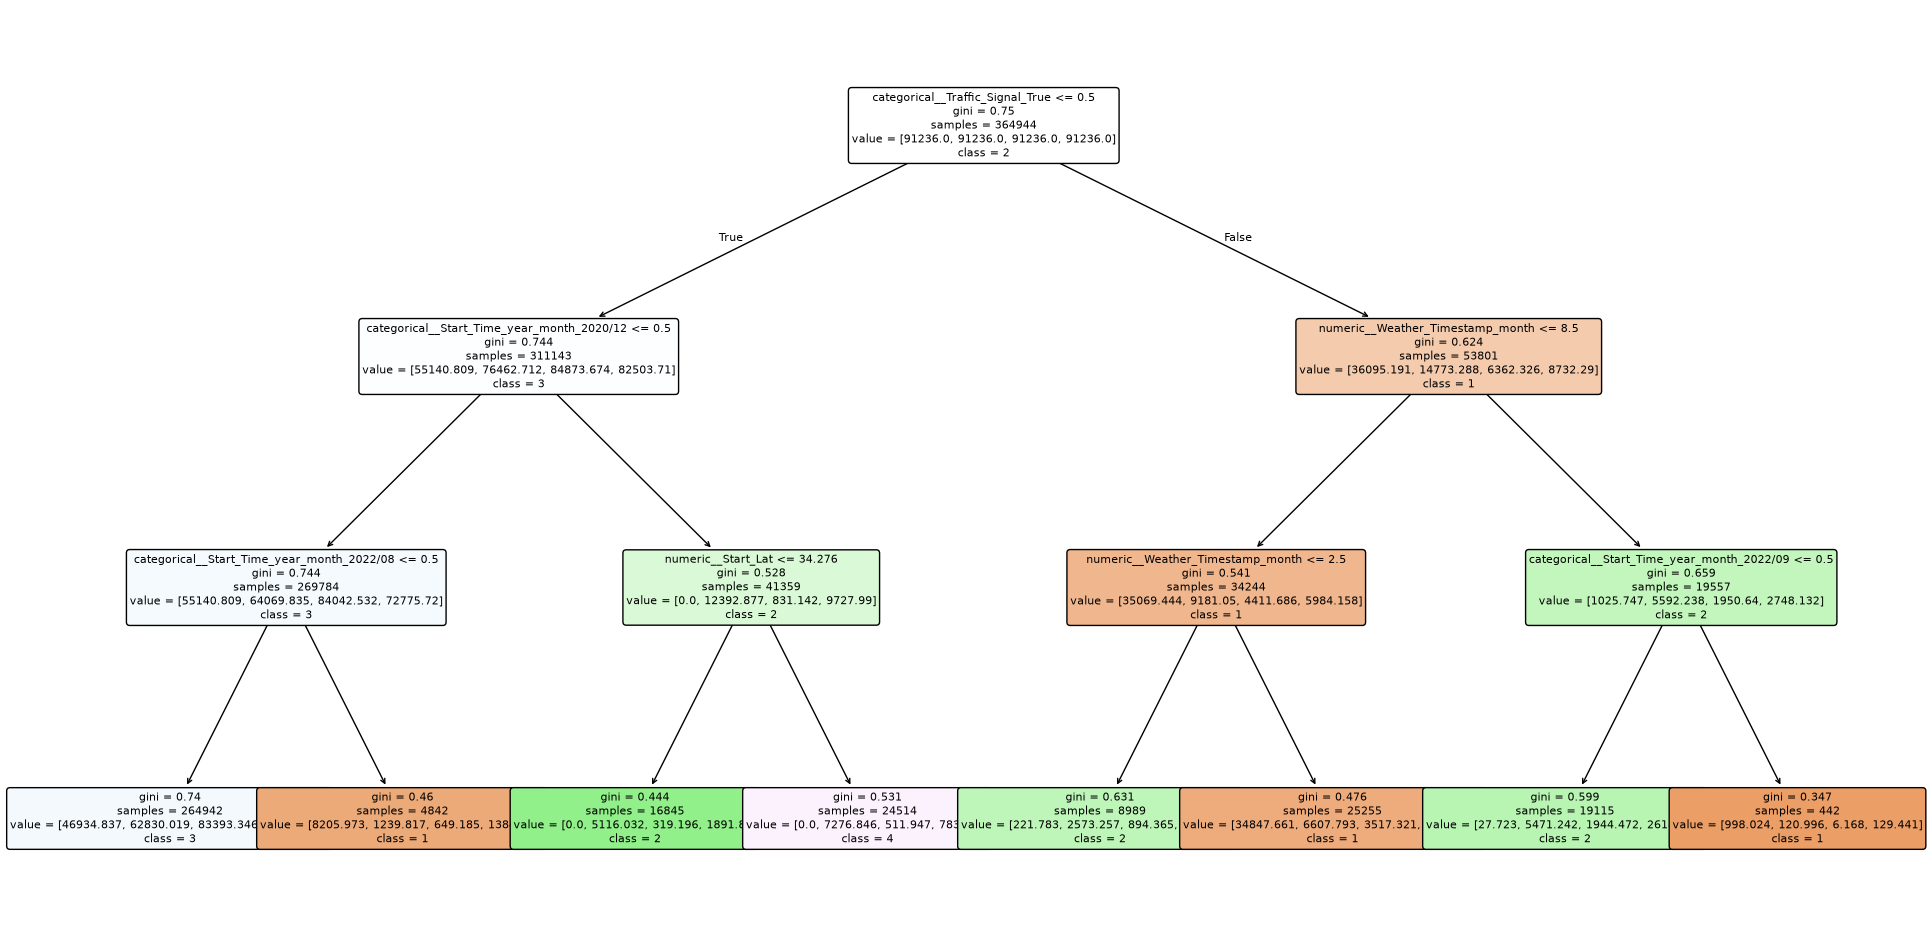

In [60]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

tree = model.named_steps["tree"]
preprocessor = model.named_steps["preprocessor"]

feature_names = preprocessor.get_feature_names_out()

plt.figure(figsize=(24, 12))

plot_tree(
    tree,
    feature_names=feature_names,
    class_names=[str(c) for c in tree.classes_],
    filled=True,
    rounded=True,
    max_depth=3,       # only display the first 3 levels
    fontsize=8
)

plt.show()

In [79]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Keep only numeric and True/False columns
X_simple = X.select_dtypes(include=["number", "bool"]).copy()

# Convert Boolean columns to 0/1
for col in X_simple.select_dtypes(include="bool").columns:
    X_simple[col] = X_simple[col].astype(int)

# Fill missing numeric values
X_simple = X_simple.fillna(X_simple.median())

X_train, X_test, y_train, y_test = train_test_split(
    X_simple,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

tree = DecisionTreeClassifier(
    max_depth=4,
    class_weight="balanced",
    random_state=42
)

tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are con

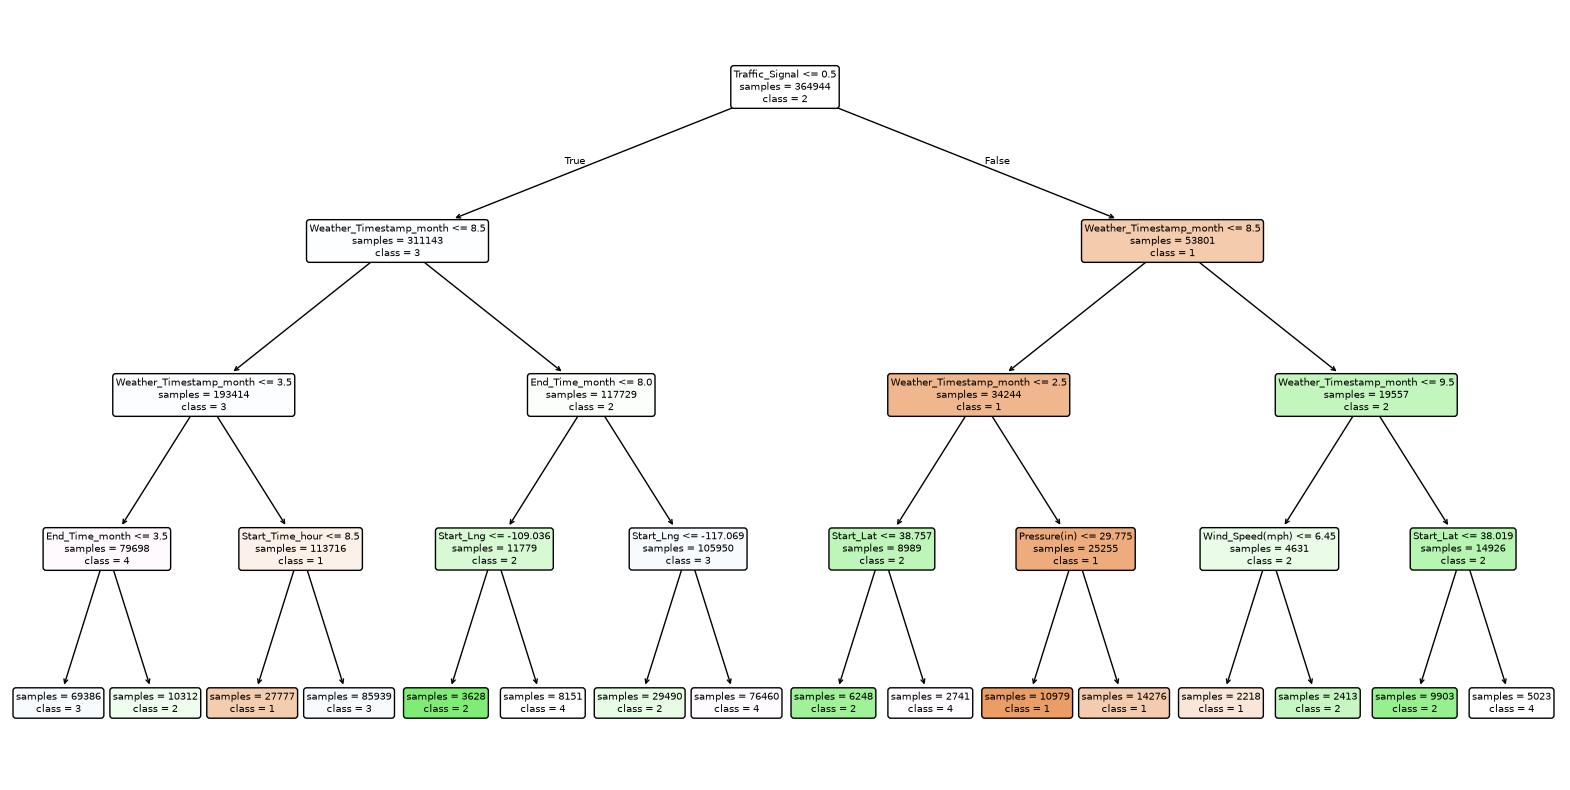

In [80]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

labels = plot_tree(
    tree,
    feature_names=X_simple.columns,
    class_names=[str(c) for c in tree.classes_],
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=7
)

for label in labels:
    lines = label.get_text().split("\n")

    filtered_lines = [
        line for line in lines
        if not line.startswith("value")
    ]

    label.set_text("\n".join(filtered_lines))

plt.show()